In [2]:
import pandas as pd

df = pd.read_csv(
    "/content/household_power_consumption.txt",
    sep=";",
    na_values=["?", ""],
    low_memory=False
)

print("Satır ve sütun sayısı:", df.shape)
display(df.head())


Satır ve sütun sayısı: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [3]:
# 1. Tarih ve saati birleştir
df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

# 2. Ölçüm sütunlarını sayısal tipe dönüştür
measurement_cols = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

df[measurement_cols] = df[measurement_cols].apply(
    pd.to_numeric, errors="coerce"
)

# 3. Tarihe göre sırala
df = df.sort_values("datetime").reset_index(drop=True)

# 4. Kontrol sonuçlarını göster
print("İlk tarih:", df["datetime"].min())
print("Son tarih:", df["datetime"].max())

print("\nGeçersiz tarih-saat sayısı:",
      df["datetime"].isna().sum())

print("Tekrarlanan tarih-saat sayısı:",
      df.loc[df["datetime"].notna(), "datetime"].duplicated().sum())

print("\nEksik değerler:")
display(pd.DataFrame({
    "Eksik adet": df[measurement_cols].isna().sum(),
    "Eksik yüzde": (
        df[measurement_cols].isna().mean() * 100
    ).round(2)
}))

print("\nNegatif değer sayıları:")
display(df[measurement_cols].lt(0).sum())

İlk tarih: 2006-12-16 17:24:00
Son tarih: 2010-11-26 21:02:00

Geçersiz tarih-saat sayısı: 0
Tekrarlanan tarih-saat sayısı: 0

Eksik değerler:


,Eksik adet,Eksik yüzde
Global_active_power,25979,1.25
Global_reactive_power,25979,1.25
Voltage,25979,1.25
Global_intensity,25979,1.25
Sub_metering_1,25979,1.25
Sub_metering_2,25979,1.25
Sub_metering_3,25979,1.25



Negatif değer sayıları:


,0
Global_active_power,0
Global_reactive_power,0
Voltage,0
Global_intensity,0
Sub_metering_1,0
Sub_metering_2,0
Sub_metering_3,0


In [4]:
# Eksikler tüm ölçüm sütunlarında aynı satırlarda mı?
missing = df[measurement_cols].isna()

same_pattern = missing.eq(
    missing["Global_active_power"], axis=0
).all().all()

print("Eksikler tüm sütunlarda aynı satırlarda mı?:", same_pattern)

# Zaman çizelgesinde bulunmayan dakikaları da kontrol et
expected_times = pd.date_range(
    start=df["datetime"].min(),
    end=df["datetime"].max(),
    freq="min"
)

absent_times = expected_times.difference(
    pd.DatetimeIndex(df["datetime"])
)

print("Zaman çizelgesinde bulunmayan dakika sayısı:", len(absent_times))

# Toplam aktif güç için kesintisiz dakika çizelgesi oluştur
power = (
    df.set_index("datetime")["Global_active_power"]
      .reindex(expected_times)
)

# Art arda gelen eksik ölçümleri gruplandır
is_missing = power.isna()
group_id = is_missing.ne(is_missing.shift()).cumsum()

gap_rows = pd.DataFrame({
    "Baslangic": power.index,
    "Bitis": power.index,
    "grup": group_id.to_numpy()
}).loc[is_missing.to_numpy()]

gaps = gap_rows.groupby("grup").agg(
    Baslangic=("Baslangic", "min"),
    Bitis=("Bitis", "max"),
    Eksik_dakika=("Baslangic", "size")
).reset_index(drop=True)

print("\nToplam kesinti sayısı:", len(gaps))

print("\nKesinti uzunluklarının dağılımı:")
categories = pd.cut(
    gaps["Eksik_dakika"],
    bins=[0, 5, 60, 1440, float("inf")],
    labels=[
        "1–5 dakika",
        "6–60 dakika",
        "61 dakika–24 saat",
        "24 saatten uzun"
    ]
)
display(categories.value_counts(sort=False).rename("Kesinti sayısı"))

print("\nEn uzun 10 kesinti:")
display(
    gaps.sort_values("Eksik_dakika", ascending=False).head(10)
)

Eksikler tüm sütunlarda aynı satırlarda mı?: True
Zaman çizelgesinde bulunmayan dakika sayısı: 0

Toplam kesinti sayısı: 71

Kesinti uzunluklarının dağılımı:


,Kesinti sayısı
Eksik_dakika,
1–5 dakika,55
6–60 dakika,7
61 dakika–24 saat,3
24 saatten uzun,6



En uzun 10 kesinti:


,Baslangic,Bitis,Eksik_dakika
68,2010-08-17 21:02:00,2010-08-22 21:27:00,7226
69,2010-09-25 03:56:00,2010-09-28 19:12:00,5237
6,2007-04-28 00:21:00,2007-04-30 14:23:00,3723
49,2009-06-13 00:30:00,2009-06-15 07:34:00,3305
58,2010-01-12 14:53:00,2010-01-14 19:01:00,3129
62,2010-03-20 03:52:00,2010-03-21 13:38:00,2027
51,2009-08-13 05:00:00,2009-08-13 19:50:00,891
15,2007-07-15 16:49:00,2007-07-15 18:11:00,83
38,2008-12-10 10:48:00,2008-12-10 11:57:00,70
16,2007-07-15 18:21:00,2007-07-15 19:07:00,47


In [5]:
# Dakikalık toplam aktif güç
power = (
    df.set_index("datetime")["Global_active_power"]
      .sort_index()
)

# Her saat için mevcut ve geçerli ölçüm sayıları
hourly = pd.DataFrame({
    "record_count": power.resample("h").size(),
    "valid_minutes": power.resample("h").count()
})

# Yalnızca 60 geçerli ölçüm varsa saatlik enerji hesaplanır
hourly["energy_kwh"] = (
    power.resample("h").sum(min_count=60) / 60
)

# Tam ve güvenilir saatleri işaretle
hourly["is_complete"] = (
    hourly["record_count"].eq(60)
    & hourly["valid_minutes"].eq(60)
)

hourly.loc[~hourly["is_complete"], "energy_kwh"] = float("nan")
hourly.index.name = "datetime"

print("Toplam saat:", len(hourly))
print("Tam ölçümlü saat:", hourly["is_complete"].sum())
print("Eksik / kısmi saat:", (~hourly["is_complete"]).sum())

print(
    "Tam ölçümlü saat oranı (%):",
    round(hourly["is_complete"].mean() * 100, 2)
)

print("\nİlk 10 saat:")
display(hourly.head(10))

print("\nGeçerli saatlik tüketimlerin özeti (kWh):")
display(hourly["energy_kwh"].describe())

Toplam saat: 34589
Tam ölçümlü saat: 34085
Eksik / kısmi saat: 504
Tam ölçümlü saat oranı (%): 98.54

İlk 10 saat:


,record_count,valid_minutes,energy_kwh,is_complete
datetime,,,,
2006-12-16 17:00:00,36,36,NaN,False
2006-12-16 18:00:00,60,60,3.632200,True
2006-12-16 19:00:00,60,60,3.400233,True
2006-12-16 20:00:00,60,60,3.268567,True
2006-12-16 21:00:00,60,60,3.056467,True
2006-12-16 22:00:00,60,60,2.200133,True
2006-12-16 23:00:00,60,60,2.061600,True
2006-12-17 00:00:00,60,60,1.882467,True
2006-12-17 01:00:00,60,60,3.349400,True



Geçerli saatlik tüketimlerin özeti (kWh):


,energy_kwh
count,34085.000000
mean,1.090361
std,0.896738
min,0.124000
25%,0.341700
50%,0.801833
75%,1.578133
max,6.560533


In [6]:
# Zaman çizelgesi ve tüketim kontrolleri
assert hourly.index.is_unique, "Tekrarlanan saat var!"
assert hourly.index.is_monotonic_increasing, "Saatler sıralı değil!"

assert (
    hourly.index.to_series().diff().dropna()
    == pd.Timedelta(hours=1)
).all(), "Zaman çizelgesinde atlanan saat var!"

assert (
    hourly["energy_kwh"].notna() == hourly["is_complete"]
).all(), "Tam ölçüm işareti ile tüketim alanı uyuşmuyor!"

assert hourly["energy_kwh"].dropna().ge(0).all(), "Negatif tüketim var!"

print("Tüm kontroller geçti.")

# Saatlik tabloyu kaydet
output_path = "/content/household_hourly_clean.csv"
hourly.to_csv(output_path, index=True)

# Bilgisayarına indir
from google.colab import files
files.download(output_path)

Tüm kontroller geçti.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
hourly.to_csv("/content/household_hourly_clean.csv", index=True)

from google.colab import files
files.download("/content/household_hourly_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
import numpy as np
import pandas as pd

# Saatlik zaman çizelgesini koru
model_data = hourly[["energy_kwh"]].copy().asfreq("h")

# Tahmin edeceğimiz saatin takvim bilgileri
model_data["hour"] = model_data.index.hour
model_data["day_of_week"] = model_data.index.dayofweek
model_data["month"] = model_data.index.month
model_data["is_weekend"] = (
    model_data.index.dayofweek >= 5
).astype(int)

# Önceki günlerin aynı saatindeki tüketimler
# Kaydırmaları boş saatleri silmeden yapıyoruz.
for days in [1, 2, 3, 7]:
    model_data[f"lag_{days}d"] = (
        model_data["energy_kwh"].shift(24 * days)
    )

# Günün başında bilinen, önceki TAM günün tüketim özeti
daily = model_data["energy_kwh"].resample("D").agg(
    ["count", "mean", "max"]
)

# Eksik ölçümlü günlerden günlük özet üretme
daily.loc[daily["count"] != 24, ["mean", "max"]] = np.nan

previous_day = daily[["mean", "max"]].shift(1)

model_data["previous_day_mean"] = (
    model_data.index.normalize().map(previous_day["mean"])
)

model_data["previous_day_max"] = (
    model_data.index.normalize().map(previous_day["max"])
)

# Modele girecek sütunlar
feature_cols = [
    "hour",
    "day_of_week",
    "month",
    "is_weekend",
    "lag_1d",
    "lag_2d",
    "lag_3d",
    "lag_7d",
    "previous_day_mean",
    "previous_day_max"
]

# Hedefi veya gerekli girdileri eksik olan satırları
# ancak geçmiş tüketim sütunları oluşturulduktan sonra çıkar
usable = model_data.dropna(
    subset=["energy_kwh"] + feature_cols
).copy()

# İlk deneyde her test günü için 24 tahmin üretebilmek adına
# yalnızca 24 kullanılabilir saati bulunan günleri tut
hours_per_day = usable.groupby(
    usable.index.normalize()
)["energy_kwh"].transform("size")

model_ready = usable.loc[hours_per_day == 24].copy()

print("Model için kullanılabilir saat:", len(model_ready))
print(
    "Model için kullanılabilir tam gün:",
    model_ready.index.normalize().nunique()
)
print("İlk tarih:", model_ready.index.min())
print("Son tarih:", model_ready.index.max())

display(model_ready.head())

Model için kullanılabilir saat: 25920
Model için kullanılabilir tam gün: 1080
İlk tarih: 2006-12-25 00:00:00
Son tarih: 2010-11-25 23:00:00


,energy_kwh,hour,day_of_week,month,is_weekend,lag_1d,lag_2d,lag_3d,lag_7d,previous_day_mean,previous_day_max
datetime,,,,,,,,,,,
2006-12-25 00:00:00,0.999567,0,0,12,0,4.028000,1.698233,0.266933,0.276367,1.770842,4.028
2006-12-25 01:00:00,1.206767,1,0,12,0,3.275700,1.722800,0.272000,0.313300,1.770842,4.028
2006-12-25 02:00:00,0.438000,2,0,12,0,2.303033,1.700767,0.267633,0.284467,1.770842,4.028
2006-12-25 03:00:00,0.589967,3,0,12,0,1.606767,1.771533,0.273867,0.309933,1.770842,4.028
2006-12-25 04:00:00,0.578667,4,0,12,0,1.576100,1.891600,0.264267,1.026333,1.770842,4.028


In [9]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# 1. Günleri kronolojik olarak ayır
days = model_ready.index.normalize().unique().sort_values()
split_index = int(len(days) * 0.80)
test_start = days[split_index]

train = model_ready.loc[model_ready.index < test_start].copy()
test = model_ready.loc[model_ready.index >= test_start].copy()

X_train = train[feature_cols]
y_train = train["energy_kwh"]

X_test = test[feature_cols]
y_test = test["energy_kwh"]

print("Eğitim dönemi:", train.index.min(), "→", train.index.max())
print("Test dönemi:", test.index.min(), "→", test.index.max())
print("Eğitim saati:", len(train))
print("Test saati:", len(test))

# 2. Basit referans tahminleri
pred_yesterday = test["lag_1d"]
pred_last_week = test["lag_7d"]

# 3. Random Forest modelini eğit
model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
pred_rf = model.predict(X_test)

# 4. Tüm yöntemleri aynı test saatlerinde değerlendir
predictions = {
    "Önceki günün aynı saati": pred_yesterday,
    "Önceki haftanın aynı saati": pred_last_week,
    "Random Forest": pred_rf
}

results = pd.DataFrame([
    {
        "Yöntem": name,
        "MAE (kWh)": mean_absolute_error(y_test, pred),
        "RMSE (kWh)": np.sqrt(mean_squared_error(y_test, pred))
    }
    for name, pred in predictions.items()
])

print("\nTest sonuçları — daha düşük hata daha iyidir:")
display(results.round(4))

# Sonraki grafik ve kayıt işlemleri için tahminleri sakla
test_predictions = pd.DataFrame({
    "actual_kwh": y_test,
    "previous_day_prediction": pred_yesterday,
    "previous_week_prediction": pred_last_week,
    "random_forest_prediction": pred_rf
})

test_predictions.index.name = "datetime"

Eğitim dönemi: 2006-12-25 00:00:00 → 2010-02-20 23:00:00
Test dönemi: 2010-02-22 00:00:00 → 2010-11-25 23:00:00
Eğitim saati: 20736
Test saati: 5184

Test sonuçları — daha düşük hata daha iyidir:


,Yöntem,MAE (kWh),RMSE (kWh)
0,Önceki günün aynı saati,0.5134,0.7662
1,Önceki haftanın aynı saati,0.5546,0.8047
2,Random Forest,0.4205,0.5827


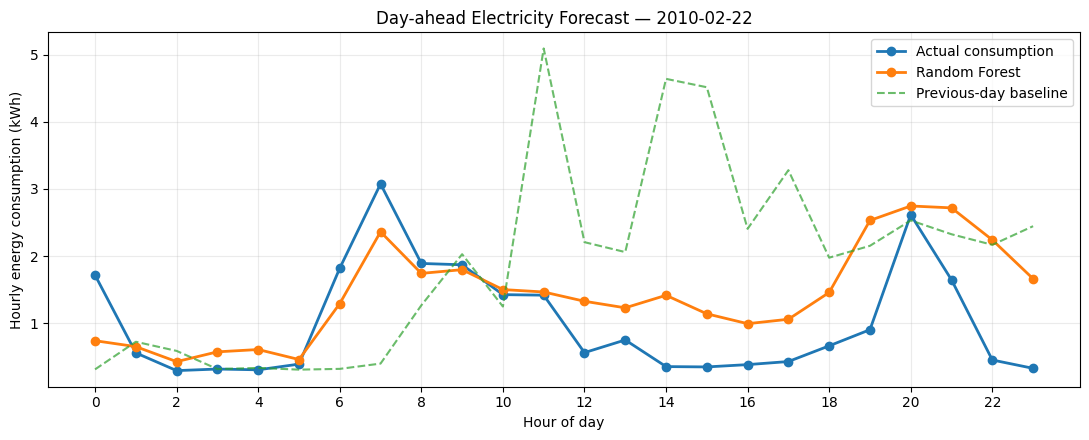

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
import matplotlib.pyplot as plt
from pathlib import Path
import zipfile
from google.colab import files

output_dir = Path("/content/assignment1_results")
output_dir.mkdir(exist_ok=True)

# Sonuç tablosunu ve tüm test tahminlerini kaydet
results.to_csv(
    output_dir / "model_comparison.csv",
    index=False
)

test_predictions.to_csv(
    output_dir / "test_predictions.csv",
    index=True
)

# Önceden belirlenmiş örnek: ilk test günü
# En iyi görünen günü seçmiyoruz.
first_test_day = test_predictions.index.min().normalize()

example = test_predictions.loc[
    test_predictions.index.normalize() == first_test_day
]

fig, ax = plt.subplots(figsize=(11, 4.5))

ax.plot(
    example.index.hour,
    example["actual_kwh"],
    label="Actual consumption",
    marker="o",
    linewidth=2
)

ax.plot(
    example.index.hour,
    example["random_forest_prediction"],
    label="Random Forest",
    marker="o",
    linewidth=2
)

ax.plot(
    example.index.hour,
    example["previous_day_prediction"],
    label="Previous-day baseline",
    linestyle="--",
    alpha=0.7
)

ax.set_title(
    f"Day-ahead Electricity Forecast — {first_test_day:%Y-%m-%d}"
)
ax.set_xlabel("Hour of day")
ax.set_ylabel("Hourly energy consumption (kWh)")
ax.set_xticks(range(0, 24, 2))
ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()
fig.savefig(
    output_dir / "first_test_day_forecast.png",
    dpi=200
)
plt.show()

# Üç dosyayı tek ZIP olarak indir
zip_path = Path("/content/assignment1_results.zip")

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in sorted(output_dir.iterdir()):
        if path.is_file():
            archive.write(path, arcname=path.name)

files.download(str(zip_path))